In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
file_path = Path(r"C:/Users/nikol/Documents/New_NBA/data/raw/player_game_logs_2025_26.parquet")
df = pd.read_parquet(file_path)
df


,SEASON_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,...,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,FANTASY_PTS,VIDEO_AVAILABLE
0,22025,203110,Draymond Green,1610612744,GSW,Golden State Warriors,0022500002,2025-10-21,GSW @ LAL,W,...,7,9,1,2,4,5,8,20,34.9,1
1,22025,1627780,Gary Payton II,1610612744,GSW,Golden State Warriors,0022500002,2025-10-21,GSW @ LAL,W,...,2,1,1,1,3,3,6,3,12.9,1
2,22025,203500,Steven Adams,1610612745,HOU,Houston Rockets,0022500001,2025-10-21,HOU @ OKC,L,...,13,3,0,0,3,4,4,2,21.1,1
3,22025,1630578,Alperen Sengun,1610612745,HOU,Houston Rockets,0022500001,2025-10-21,HOU @ OKC,L,...,11,7,2,1,4,5,39,9,67.7,1
4,22025,1631106,Tari Eason,1610612745,HOU,Houston Rockets,0022500001,2025-10-21,HOU @ OKC,L,...,6,0,0,1,4,1,3,-4,9.2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26646,22025,1642860,Will Riley,1610612764,WAS,Washington Wizards,0022501187,2026-04-12,WAS @ CLE,L,...,5,4,0,0,2,2,6,-8,16.0,1
26647,22025,1630191,Isaiah Stewart,1610612765,DET,Detroit Pistons,0022501188,2026-04-12,DET @ IND,W,...,5,0,0,1,2,3,16,-9,23.0,1
26648,22025,1630194,Paul Reed,1610612765,DET,Detroit Pistons,0022501188,2026-04-12,DET @ IND,W,...,6,3,3,3,0,1,26,28,55.7,1
26649,22025,1642449,Tolu Smith,1610612765,DET,Detroit Pistons,0022501188,2026-04-12,DET @ IND,W,...,3,1,0,0,0,1,5,-4,10.1,1


In [2]:
missing = df.isna().sum()
print(missing[missing > 0])

FG_PCT      1311
FG3_PCT     5241
FT_PCT     11717
dtype: int64


In [3]:
df['Two-Pointers_A'] = df['FGA'] - df['FG3A']
df["Two-Pointers_A"]

0         3
1         5
2         4
3        16
4         2
         ..
26646     8
26647     7
26648    11
26649     2
26650     6
Name: Two-Pointers_A, Length: 26651, dtype: int64

In [4]:
df['Two-Pointers_M'] = df['FGM'] - df['FG3M']
print(df.columns.tolist())

['SEASON_ID', 'PLAYER_ID', 'PLAYER_NAME', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'FANTASY_PTS', 'VIDEO_AVAILABLE', 'Two-Pointers_A', 'Two-Pointers_M']


In [5]:
df['GAME_DATE'] = pd.to_datetime(df['GAME_DATE'])

dates = sorted(df['GAME_DATE'].unique())
date_mod = int(len(dates) * 0.70)
split_date = dates[date_mod]

train_df = df[df['GAME_DATE'] < split_date].copy()
test_df = df[df['GAME_DATE'] >= split_date].copy()

In [6]:
player_stats = train_df.groupby(
    ['PLAYER_ID', "PLAYER_NAME"]
)[
    ['Two-Pointers_A', 'Two-Pointers_M', 
     'FG3A', 'FG3M', 'FTA', 'FTM']
].sum().reset_index()
display(player_stats.head())

,PLAYER_ID,PLAYER_NAME,Two-Pointers_A,Two-Pointers_M,FG3A,FG3M,FTA,FTM
0,2544,LeBron James,431,248,170,52,203,152
1,101108,Chris Paul,26,8,30,10,2,1
2,200768,Kyle Lowry,0,0,10,3,4,3
3,201142,Kevin Durant,622,348,292,118,313,276
4,201143,Al Horford,83,48,151,50,19,17


In [7]:
player_stats['Total_Attempts'] = (
    player_stats['Two-Pointers_A'] 
    + player_stats['FG3A']
    + player_stats['FTA']
)

In [8]:
player_stats['TwoP_Rate'] = (
    player_stats['Two-Pointers_A'] / player_stats['Total_Attempts']
)

player_stats['ThreeP_Rate'] = (
    player_stats['FG3A'] / player_stats['Total_Attempts']
)

player_stats['FtP_Rate'] = (
    player_stats['FTA'] / player_stats['Total_Attempts']
)

In [9]:
print((player_stats['Total_Attempts'] == 0).sum())

2


In [10]:
player_stats = player_stats[
    player_stats['Total_Attempts'] > 0
].copy()

In [ ]:
alpha = 1 
beta = 1

player_stats['alpha_post'] = alpha + player_stats['FG3A']
player_stats['beta_post'] = beta + player_stats['Two-Pointers_A']

player_stats['p_3pt_mean'] = (
    player_stats['alpha_post'] / (player_stats['alpha_post'] + player_stats['beta_post'])
)

display(player_stats[
    ['PLAYER_NAME', 'FG3A', "Two-Pointers_A", 'p_3pt_mean']
].head())


,PLAYER_NAME,FG3A,Two-Pointers_A,p_3pt_mean
0,LeBron James,170,431,0.283582
1,Chris Paul,30,26,0.534483
2,Kyle Lowry,10,0,0.916667
3,Kevin Durant,292,622,0.319869
4,Al Horford,151,83,0.644068


In [12]:
%pip install matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


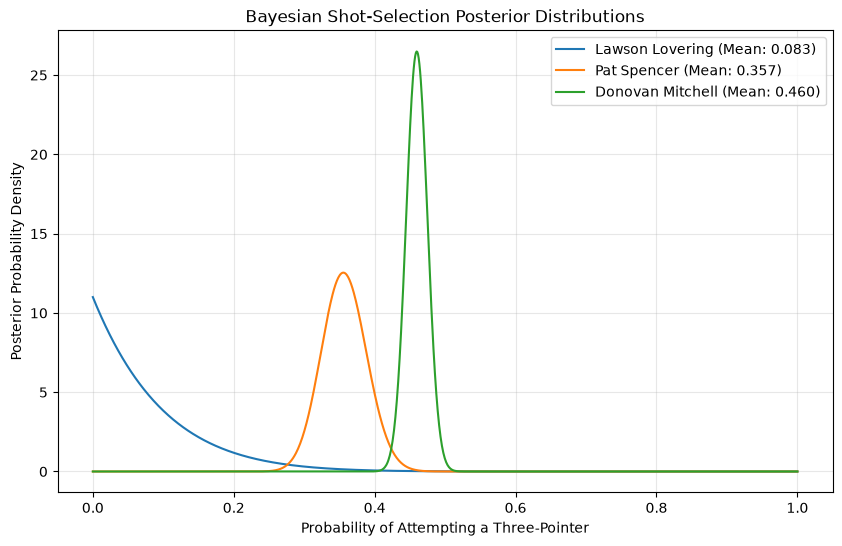

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Select three players to compare

# Possible probabilities from 0 to 1
x = np.linspace(0, 1, 1000)

plt.figure(figsize=(10, 6))

players = sorted_stats.iloc[[0, len(sorted_stats)//2, -1]]

for _, player in players.iterrows():
    a = player['alpha_post']
    b = player['beta_post']

    y = beta.pdf(x, a, b)

    plt.plot(
        x, y,
        label=f"{player['PLAYER_NAME']} (Mean: {a/(a+b):.3f})"
    )

plt.xlabel("Probability of Attempting a Three-Pointer")
plt.ylabel("Posterior Probability Density")
plt.title("Bayesian Shot-Selection Posterior Distributions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
player_stats['CI_lower'] = beta.ppf(
    0.025,
    player_stats['alpha_post'],
    player_stats['beta_post']
)

player_stats['CI_upper'] = beta.ppf(
    0.975,
    player_stats['alpha_post'],
    player_stats['beta_post']
)

In [15]:
display(player_stats[
    ['PLAYER_NAME', 'FG3A', 'Two-Pointers_A',
     'p_3pt_mean', 'CI_lower', 'CI_upper']
].head(10))

,PLAYER_NAME,FG3A,Two-Pointers_A,p_3pt_mean,CI_lower,CI_upper
0,LeBron James,170,431,0.283582,0.248333,0.320191
1,Chris Paul,30,26,0.534483,0.406560,0.660152
2,Kyle Lowry,10,0,0.916667,0.715086,0.997701
3,Kevin Durant,292,622,0.319869,0.290061,0.350422
4,Al Horford,151,83,0.644068,0.582017,0.703805
5,Mike Conley,131,43,0.750000,0.683638,0.810982
6,Jeff Green,23,9,0.705882,0.544762,0.844083
7,Russell Westbrook,316,375,0.457431,0.420495,0.494601
8,Kevin Love,115,50,0.694611,0.622873,0.761934
9,Eric Gordon,14,7,0.652174,0.451276,0.828021


In [ ]:
sorted_stats = player_stats.sort_values('FG3A').reset_index(drop=True) 

In [27]:
player_stats['FGA_Total'] =  player_stats['Two-Pointers_A'] + player_stats['FG3A']
player_stats['ThreeP_Rate'] = (player_stats['FG3A'] / player_stats['FGA_Total'])

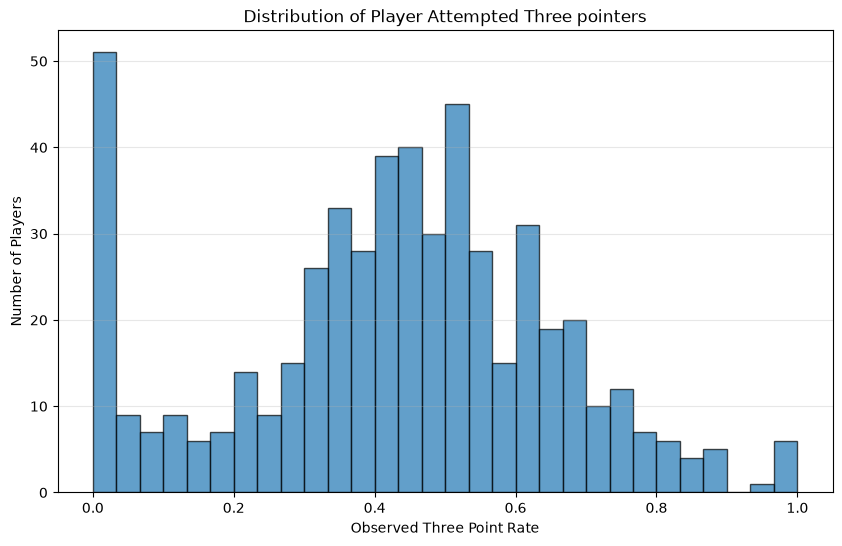

In [29]:
plt.figure(figsize=(10,6))
plt.hist(
    player_stats['ThreeP_Rate'],
    bins = 30,
    edgecolor='black',
    alpha=0.7
)
plt.xlabel('Observed Three Point Rate')
plt.ylabel('Number of Players')
plt.title('Distribution of Player Attempted Three pointers')
plt.grid(axis='y',alpha=0.3)
plt.show()

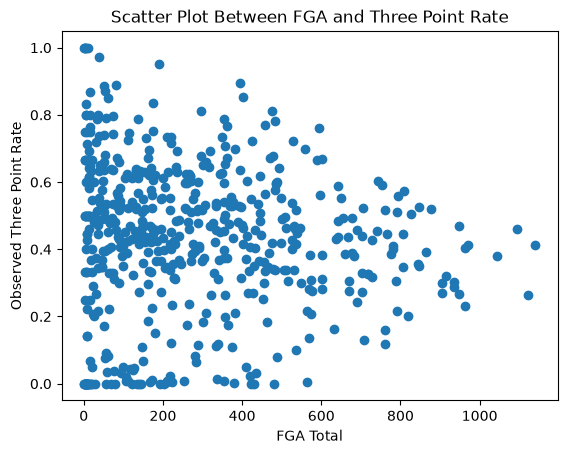

In [30]:
plt.scatter(player_stats['FGA_Total'], player_stats['ThreeP_Rate'])
plt.title('Scatter Plot Between FGA and Three Point Rate')
plt.xlabel('FGA Total')
plt.ylabel('Observed Three Point Rate')
plt.show()

In [31]:
from scipy.optimize import minimize
from scipy.special import betaln

k = player_stats['FG3A'].to_numpy()
n = player_stats['FGA_Total'].to_numpy()

# Negative log marginal likelihood
def neg_log_likelihood(log_params):
    # Exponentiate to ensure alpha and beta stay positive
    alpha, beta = np.exp(log_params)

    log_likelihood = np.sum(
        betaln(k + alpha, n - k + beta)
        - betaln(alpha, beta)
    )

    return -log_likelihood

# Estimate alpha and beta
result = minimize(
    neg_log_likelihood,
    x0=np.log([2.0, 3.0]),
    method='L-BFGS-B'
)

alpha_hat, beta_hat = np.exp(result.x)

print("Optimization successful:", result.success)
print(f"Alpha: {alpha_hat:.4f}")
print(f"Beta: {beta_hat:.4f}")
print(f"Population prior mean: {alpha_hat / (alpha_hat + beta_hat):.4f}")

Optimization successful: True
Alpha: 1.3931
Beta: 2.0278
Population prior mean: 0.4072


In [33]:
player_stats['alpha_hier'] = alpha_hat + player_stats['FG3A']
player_stats['beta_hier'] = beta_hat + player_stats['Two-Pointers_A']

player_stats['p_3pt_hier'] = (
    player_stats['alpha_hier'] /
    (player_stats['alpha_hier'] + player_stats['beta_hier'])
)

In [34]:
display(
    player_stats[
        ['PLAYER_NAME', 'FGA_Total',
         'ThreeP_Rate', 'p_3pt_mean', 'p_3pt_hier']
    ].sort_values('FGA_Total').head(10)
)

,PLAYER_NAME,FGA_Total,ThreeP_Rate,p_3pt_mean,p_3pt_hier
512,Max Shulga,1,0.000000,0.333333,0.315113
397,Tosan Evbuomwan,1,0.000000,0.333333,0.315113
531,Chris Mañon,1,1.000000,0.666667,0.541311
269,Hunter Dickinson,2,0.000000,0.250000,0.256984
119,Mo Bamba,2,0.000000,0.250000,0.256984
506,Vladislav Goldin,2,0.000000,0.250000,0.256984
485,Noa Essengue,3,0.666667,0.600000,0.528443
374,Colby Jones,3,0.666667,0.600000,0.528443
435,Trentyn Flowers,3,0.333333,0.400000,0.372702
68,Cameron Payne,3,1.000000,0.800000,0.684185


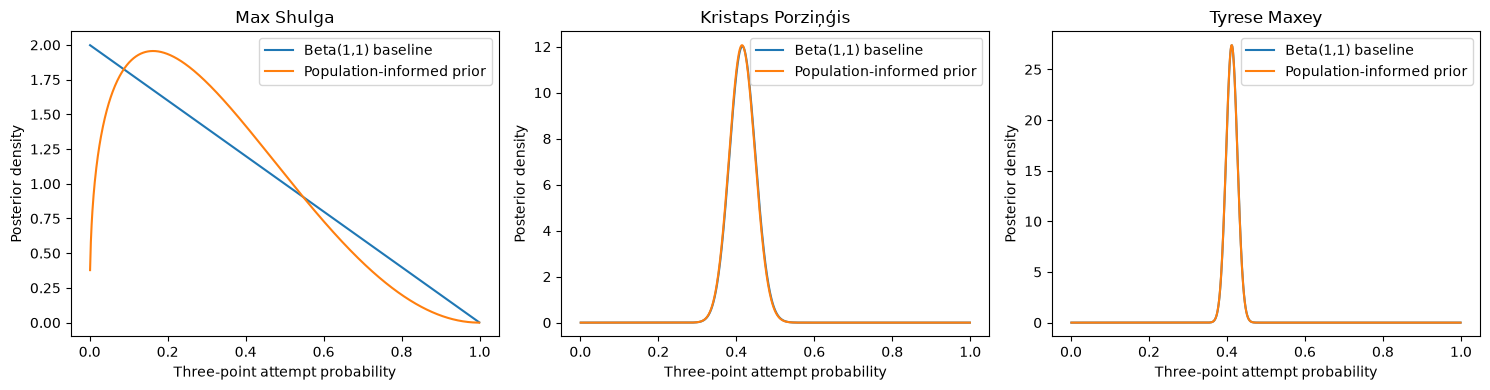

In [35]:
players = player_stats.sort_values(
    'FGA_Total'
).iloc[[0, len(player_stats)//2, -1]]

x = np.linspace(0.001, 0.999, 1000)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (_, player) in zip(axes, players.iterrows()):
    original = beta.pdf(
        x, player['alpha_post'], player['beta_post']
    )

    hierarchical = beta.pdf(
        x, player['alpha_hier'], player['beta_hier']
    )

    ax.plot(x, original, label='Beta(1,1) baseline')
    ax.plot(x, hierarchical, label='Population-informed prior')

    ax.set_title(player['PLAYER_NAME'])
    ax.set_xlabel('Three-point attempt probability')
    ax.set_ylabel('Posterior density')
    ax.legend()

plt.tight_layout()
plt.show()

In [36]:
model_cols = [
    'PLAYER_ID',
    'p_3pt_mean',
    'p_3pt_hier',
    'alpha_post',
    'beta_post',
    'alpha_hier',
    'beta_hier'
]

test_predictions = test_df.merge(
    player_stats[model_cols],
    on='PLAYER_ID',
    how='left',
    validate='many_to_one'
)

print("Test observations:", len(test_predictions))
print("Missing player estimates:",
      test_predictions['p_3pt_hier'].isna().sum())

Test observations: 8471
Missing player estimates: 397


In [37]:
eval_df = test_predictions[
    test_predictions['p_3pt_hier'].notna()
    & (test_predictions['FGA'] > 0)
].copy()

print("Evaluated observations:", len(eval_df))

Evaluated observations: 7712


In [38]:
eval_df['pred_3PA_base'] = (
    eval_df['FGA'] * eval_df['p_3pt_mean']
)

eval_df['pred_3PA_hier'] = (
    eval_df['FGA'] * eval_df['p_3pt_hier']
)

In [40]:
%pip install scikit-learn
from sklearn.metrics import mean_absolute_error

mae_base = mean_absolute_error(
    eval_df['FG3A'],
    eval_df['pred_3PA_base']
)

mae_hier = mean_absolute_error(
    eval_df['FG3A'],
    eval_df['pred_3PA_hier']
)

print(f"Baseline MAE: {mae_base:.4f}")
print(f"Hierarchical MAE: {mae_hier:.4f}")

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ------------------------- -------------- 5.2/8.3 MB 35.6 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 46.5 MB/s  0:00:00

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   ---------------- ----------------------- 2/5 [cloudpickle]
   ------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Baseline MAE: 1.0992
Hierarchical MAE: 1.0993


In [41]:
from scipy.stats import betabinom

eval_df['log_prob_base'] = betabinom.logpmf(
    eval_df['FG3A'],
    eval_df['FGA'],
    eval_df['alpha_post'],
    eval_df['beta_post']
)

eval_df['log_prob_hier'] = betabinom.logpmf(
    eval_df['FG3A'],
    eval_df['FGA'],
    eval_df['alpha_hier'],
    eval_df['beta_hier']
)

In [42]:
nll_base = -eval_df['log_prob_base'].mean()
nll_hier = -eval_df['log_prob_hier'].mean()

print(f"Baseline NLL: {nll_base:.4f}")
print(f"Hierarchical NLL: {nll_hier:.4f}")

Baseline NLL: 1.5712
Hierarchical NLL: 1.5701


In [43]:
rng = np.random.default_rng(42)
n_sims = 10000

game = eval_df.iloc[0]

p_draws = rng.beta(
    game['alpha_hier'],
    game['beta_hier'],
    size=n_sims
)

sim_3pa = rng.binomial(
    n=int(game['FGA']),
    p=p_draws
)

print("Player:", game['PLAYER_NAME'])
print("Actual 3PA:", game['FG3A'])
print("Simulated mean:", sim_3pa.mean())
print("95% predictive interval:", np.quantile(sim_3pa, [0.025, 0.975]))

Player: Patrick Williams
Actual 3PA: 4
Simulated mean: 2.6721
95% predictive interval: [1. 5.]


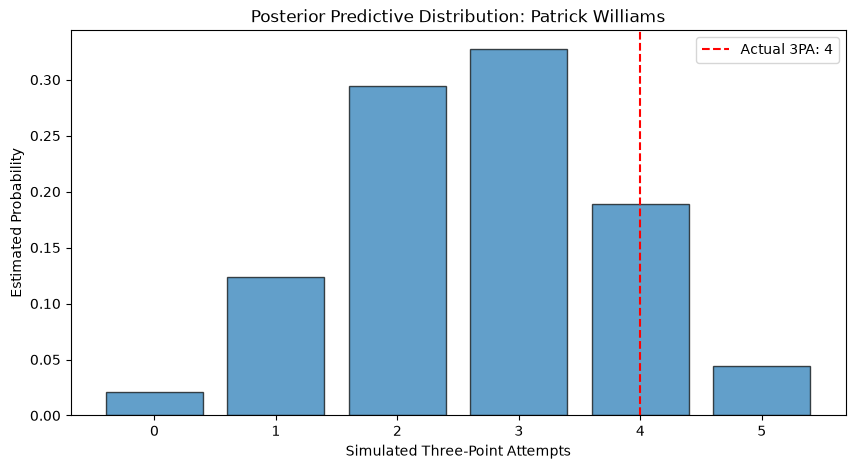

In [44]:
values, counts = np.unique(sim_3pa, return_counts=True)

plt.figure(figsize=(10, 5))

plt.bar(values, counts / n_sims, alpha=0.7, edgecolor='black')

plt.axvline(
    game['FG3A'],
    color='red',
    linestyle='--',
    label=f"Actual 3PA: {game['FG3A']}"
)

plt.xlabel("Simulated Three-Point Attempts")
plt.ylabel("Estimated Probability")
plt.title(f"Posterior Predictive Distribution: {game['PLAYER_NAME']}")
plt.legend()
plt.show()

In [45]:
exact_mean = (
    game['FGA'] * game['p_3pt_hier']
)

print(f"Monte Carlo mean: {sim_3pa.mean():.4f}")
print(f"Exact mean:       {exact_mean:.4f}")

Monte Carlo mean: 2.6721
Exact mean:       2.6800


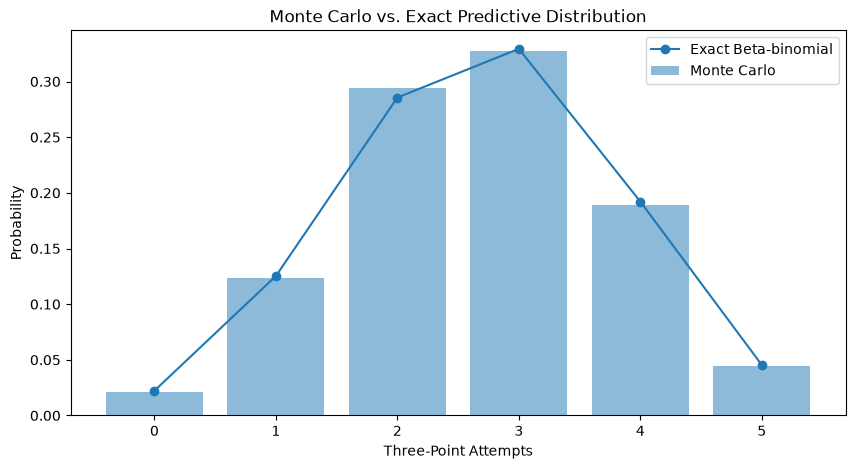

In [46]:
x = np.arange(int(game['FGA']) + 1)

exact_probs = betabinom.pmf(
    x,
    int(game['FGA']),
    game['alpha_hier'],
    game['beta_hier']
)

plt.figure(figsize=(10, 5))

plt.bar(
    values,
    counts / n_sims,
    alpha=0.5,
    label='Monte Carlo'
)

plt.plot(
    x,
    exact_probs,
    'o-',
    label='Exact Beta-binomial'
)

plt.xlabel("Three-Point Attempts")
plt.ylabel("Probability")
plt.title("Monte Carlo vs. Exact Predictive Distribution")
plt.legend()
plt.show()

In [47]:
# Calculate 95% predictive intervals
eval_df['lower_95'] = betabinom.ppf(
    0.025,
    eval_df['FGA'],
    eval_df['alpha_hier'],
    eval_df['beta_hier']
)

eval_df['upper_95'] = betabinom.ppf(
    0.975,
    eval_df['FGA'],
    eval_df['alpha_hier'],
    eval_df['beta_hier']
)

# Determine whether actual 3PA falls within the interval
eval_df['covered_95'] = (
    (eval_df['FG3A'] >= eval_df['lower_95']) &
    (eval_df['FG3A'] <= eval_df['upper_95'])
)

coverage = eval_df['covered_95'].mean()
avg_width = (
    eval_df['upper_95'] - eval_df['lower_95']
).mean()

print(f"95% interval coverage: {coverage:.2%}")
print(f"Average interval width: {avg_width:.2f} attempts")

95% interval coverage: 97.41%
Average interval width: 4.71 attempts


In [48]:
eval_df['volume_group'] = pd.cut(
    eval_df['FGA'],
    bins=[0, 5, 12, float('inf')],
    labels=['Low (1-5)', 'Medium (6-12)', 'High (13+)']
)

volume_results = eval_df.groupby(
    'volume_group',
    observed=True
).agg(
    games=('FG3A', 'size'),
    coverage=('covered_95', 'mean'),
    avg_width=('upper_95', lambda x: 0)  # Replaced below
)

eval_df['interval_width'] = (
    eval_df['upper_95'] - eval_df['lower_95']
)

volume_results = eval_df.groupby(
    'volume_group',
    observed=True
).agg(
    games=('FG3A', 'size'),
    coverage=('covered_95', 'mean'),
    avg_width=('interval_width', 'mean')
)

print(volume_results)

               games  coverage  avg_width
volume_group                             
Low (1-5)       2531  0.997234   2.395496
Medium (6-12)   3438  0.969459   5.067772
High (13+)      1743  0.949512   7.383247


In [49]:
eval_df['expected_coverage'] = (
    betabinom.cdf(
        eval_df['upper_95'],
        eval_df['FGA'],
        eval_df['alpha_hier'],
        eval_df['beta_hier']
    )
    -
    betabinom.cdf(
        eval_df['lower_95'] - 1,
        eval_df['FGA'],
        eval_df['alpha_hier'],
        eval_df['beta_hier']
    )
)

coverage_comparison = eval_df.groupby(
    'volume_group',
    observed=True
).agg(
    games=('FG3A', 'size'),
    observed_coverage=('covered_95', 'mean'),
    expected_coverage=('expected_coverage', 'mean')
)

coverage_comparison['difference'] = (
    coverage_comparison['observed_coverage']
    - coverage_comparison['expected_coverage']
)

print(coverage_comparison.round(4))

               games  observed_coverage  expected_coverage  difference
volume_group                                                          
Low (1-5)       2531             0.9972             0.9954      0.0019
Medium (6-12)   3438             0.9695             0.9823     -0.0129
High (13+)      1743             0.9495             0.9742     -0.0247


In [50]:
eval_df['below_interval'] = (
    eval_df['FG3A'] < eval_df['lower_95']
)

eval_df['above_interval'] = (
    eval_df['FG3A'] > eval_df['upper_95']
)

tail_results = eval_df.groupby(
    'volume_group',
    observed=True
).agg(
    below_rate=('below_interval', 'mean'),
    above_rate=('above_interval', 'mean')
)

print((tail_results * 100).round(2))

               below_rate  above_rate
volume_group                         
Low (1-5)            0.12        0.16
Medium (6-12)        1.60        1.45
High (13+)           2.75        2.29


In [51]:
eval_df['pred_variance'] = betabinom.var(
    eval_df['FGA'],
    eval_df['alpha_hier'],
    eval_df['beta_hier']
)

eval_df['standardized_error'] = (
    (eval_df['FG3A'] - eval_df['pred_3PA_hier'])
    / np.sqrt(eval_df['pred_variance'])
)

eval_df['squared_z'] = eval_df['standardized_error'] ** 2

variance_results = eval_df.groupby(
    'volume_group',
    observed=True
).agg(
    mean_z=('standardized_error', 'mean'),
    mean_squared_z=('squared_z', 'mean')
)

print(variance_results.round(4))

               mean_z  mean_squared_z
volume_group                         
Low (1-5)      0.0216          0.9033
Medium (6-12) -0.0557          1.1346
High (13+)    -0.1073          1.2370


In [52]:
# Chronological split within the original training period
train_dates = sorted(train_df['GAME_DATE'].unique())

val_split_idx = int(len(train_dates) * 0.80)
val_split_date = train_dates[val_split_idx]

fit_df = train_df[
    train_df['GAME_DATE'] < val_split_date
].copy()

val_df = train_df[
    train_df['GAME_DATE'] >= val_split_date
].copy()

print("Fit observations:", len(fit_df))
print("Validation observations:", len(val_df))
print("Test observations:", len(test_df))

print("\nFit period:",
      fit_df['GAME_DATE'].min(),
      "to", fit_df['GAME_DATE'].max())

print("Validation period:",
      val_df['GAME_DATE'].min(),
      "to", val_df['GAME_DATE'].max())

Fit observations: 14416
Validation observations: 3764
Test observations: 8471

Fit period: 2025-10-21 00:00:00 to 2026-01-22 00:00:00
Validation period: 2026-01-23 00:00:00 to 2026-02-20 00:00:00


In [53]:
fit_stats = (
    fit_df.groupby('PLAYER_ID')
    .agg(
        FG3A=('FG3A', 'sum'),
        FGA_Total=('FGA', 'sum')
    )
    .reset_index()
)

# Only players with at least one field-goal attempt
fit_stats = fit_stats[
    fit_stats['FGA_Total'] > 0
].copy()

# Independent Beta(1,1) posterior
fit_stats['alpha_base'] = 1 + fit_stats['FG3A']

fit_stats['beta_base'] = (
    1 + fit_stats['FGA_Total'] - fit_stats['FG3A']
)

fit_stats['p_base'] = (
    fit_stats['alpha_base'] /
    (fit_stats['alpha_base'] + fit_stats['beta_base'])
)

print("Players fitted:", len(fit_stats))

Players fitted: 512


In [54]:
val_predictions = val_df.merge(
    fit_stats[
        ['PLAYER_ID', 'alpha_base', 'beta_base', 'p_base']
    ],
    on='PLAYER_ID',
    how='left',
    validate='many_to_one'
)

val_eval = val_predictions[
    val_predictions['p_base'].notna()
    & (val_predictions['FGA'] > 0)
].copy()

print("Validation games:", len(val_eval))
print("Players:", val_eval['PLAYER_ID'].nunique())
print("Missing player estimates:",
      val_predictions['p_base'].isna().sum())

Validation games: 3536
Players: 451
Missing player estimates: 59


In [55]:
from scipy.stats import betabinom

# Expected 3PA
val_eval['pred_3PA_base'] = (
    val_eval['FGA'] * val_eval['p_base']
)

# Mean absolute error
mae_base_val = (
    val_eval['FG3A'] - val_eval['pred_3PA_base']
).abs().mean()

# Beta-binomial predictive log probability
val_eval['log_prob_base'] = betabinom.logpmf(
    val_eval['FG3A'],
    val_eval['FGA'],
    val_eval['alpha_base'],
    val_eval['beta_base']
)

nll_base_val = -val_eval['log_prob_base'].mean()

print(f"Validation MAE: {mae_base_val:.4f}")
print(f"Validation NLL: {nll_base_val:.4f}")

Validation MAE: 1.0796
Validation NLL: 1.5671


In [56]:
fit_stats['mu'] = (
    fit_stats['FG3A'] + 1
) / (
    fit_stats['FGA_Total'] + 2
)

In [57]:
fit_games = fit_df.merge(
    fit_stats[['PLAYER_ID', 'mu']],
    on='PLAYER_ID',
    how='inner',
    validate='many_to_one'
)

fit_games = fit_games[fit_games['FGA'] > 0].copy()

In [59]:
from scipy.optimize import minimize_scalar

k_fit = fit_games['FG3A'].to_numpy()
n_fit = fit_games['FGA'].to_numpy()
mu_fit = fit_games['mu'].to_numpy()

def neg_log_likelihood_phi(log_phi):
    phi = np.exp(log_phi)

    alpha = mu_fit * phi
    beta = (1 - mu_fit) * phi

    return -np.sum(
        betabinom.logpmf(k_fit, n_fit, alpha, beta)
    )

result = minimize_scalar(
    neg_log_likelihood_phi,
    bounds=(np.log(0.1), np.log(10000)),
    method='bounded'
)

phi_hat = np.exp(result.x)

print("Optimization successful:", result.success)
print(f"Estimated phi: {phi_hat:.4f}")

Optimization successful: True
Estimated phi: 9999.9516


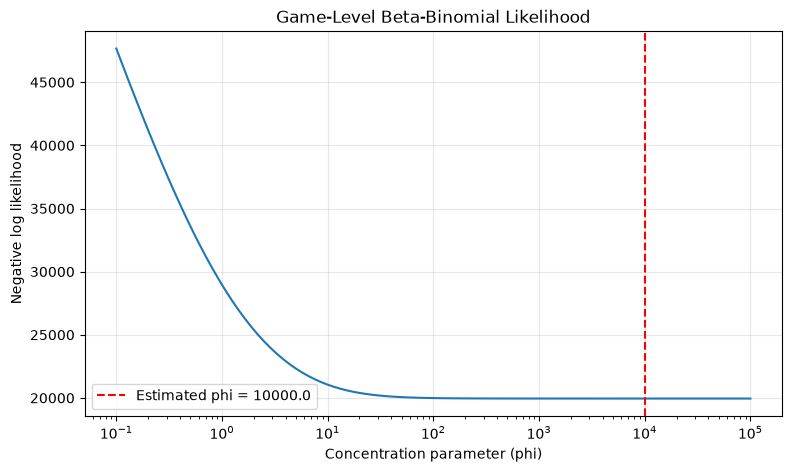

In [60]:
phi_values = np.logspace(-1, 5, 100)

nll_values = [
    neg_log_likelihood_phi(np.log(phi))
    for phi in phi_values
]

plt.figure(figsize=(9, 5))
plt.plot(phi_values, nll_values)

plt.axvline(
    phi_hat,
    color='red',
    linestyle='--',
    label=f'Estimated phi = {phi_hat:.1f}'
)

plt.xscale('log')
plt.xlabel('Concentration parameter (phi)')
plt.ylabel('Negative log likelihood')
plt.title('Game-Level Beta-Binomial Likelihood')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [61]:
import numpy as np

rng = np.random.default_rng(42)
n_sims = 10000

game = val_eval.iloc[0]

a = game['alpha_base']
b = game['beta_base']
n = int(game['FGA'])

# Temporary value for exploring the model
phi = 20

# 1. Sample player-level uncertainty
mu_draws = rng.beta(a, b, size=n_sims)

# 2. Sample game-to-game variation
p_game_draws = rng.beta(
    mu_draws * phi,
    (1 - mu_draws) * phi
)

# 3. Simulate three-point attempts
sim_3pa = rng.binomial(
    n=n,
    p=p_game_draws
)

print("Actual 3PA:", game['FG3A'])
print("Predicted mean:", sim_3pa.mean())
print("95% interval:", np.quantile(sim_3pa, [0.025, 0.975]))

Actual 3PA: 4
Predicted mean: 5.1295
95% interval: [2. 8.]


In [62]:
%pip install pymc arviz

   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 608.3/608.3 kB 11.2 MB/s  0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 36.4 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 48.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 2.8/2.8 MB 55.8 MB/s  0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   ------------------- -------------------- 20.4/41.9 MB 99.4 MB/s eta 0:00:01
   ---------------------------------------  41.7/41.9 MB 110.5 MB/s eta 0:00:01
   ---------------------------------------- 41.9/41.9 MB 95.2 MB/s  0:00:00
   ---------------------------------------- 0.0/876.3 kB ? eta -:--:--
   ---------------------------------------- 87


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:
import pymc as pm
import arviz as az

fit_games = fit_df.loc[
    fit_df['FGA'] > 0,
    ['PLAYER_ID', 'FGA', 'FG3A']
].copy()

# Map each player to an integer index
player_ids = np.sort(fit_games['PLAYER_ID'].unique())

player_index = pd.Index(player_ids).get_indexer(
    fit_games['PLAYER_ID']
)

n_players = len(player_ids)

n_attempts = fit_games['FGA'].to_numpy(dtype='int64')
k_threes = fit_games['FG3A'].to_numpy(dtype='int64')

print("Players:", n_players)
print("Player-games:", len(fit_games))
print("Valid observations:", np.all(k_threes <= n_attempts))


g++ not available, if using conda: `conda install gxx`


Players: 512
Player-games: 13670
Valid observations: True


In [64]:
from scipy.optimize import minimize
from scipy.special import betaln

fit_k = fit_stats['FG3A'].to_numpy()
fit_n = fit_stats['FGA_Total'].to_numpy()

def neg_log_marginal(log_params):
    alpha, beta = np.exp(log_params)

    return -np.sum(
        betaln(fit_k + alpha, fit_n - fit_k + beta)
        - betaln(alpha, beta)
    )

prior_result = minimize(
    neg_log_marginal,
    x0=np.log([2.0, 3.0]),
    method='L-BFGS-B'
)

assert prior_result.success

alpha_fit, beta_fit = np.exp(prior_result.x)

print(f"Alpha: {alpha_fit:.4f}")
print(f"Beta:  {beta_fit:.4f}")

Alpha: 1.3799
Beta:  1.9770


In [65]:
with pm.Model() as shot_selection_model:

    # Player-level average shot-selection probabilities
    mu = pm.Beta(
        "mu",
        alpha=alpha_fit,
        beta=beta_fit,
        shape=n_players
    )

    # Shared game-level concentration
    phi = pm.Exponential(
        "phi",
        lam=0.05
    )

    # Beta-binomial likelihood for observed games
    shots = pm.BetaBinomial(
        "shots",
        n=n_attempts,
        alpha=mu[player_index] * phi,
        beta=(1 - mu[player_index]) * phi,
        observed=k_threes
    )

In [66]:
with shot_selection_model:
    trace = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=2,
        target_accept=0.95,
        random_seed=42,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [mu, phi]


c:\Users\nikol\Documents\New_NBA\.venv\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for 
Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 487 seconds.


      mean  sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
phi  219.5  39      160      290     8515     2884  1.00      0.47    0.76


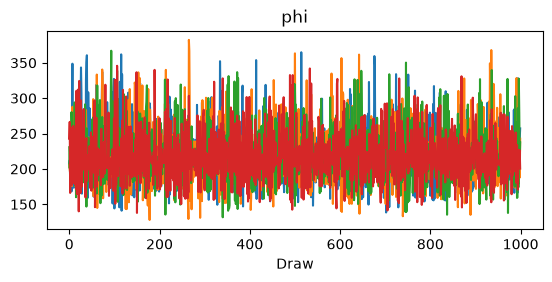

In [68]:
print(
    az.summary(
        trace,
        var_names=['phi'],
    )
)

az.plot_trace(trace, var_names=['phi'])
plt.show()